# La batería de validación IFRS 9 en seis fechas de reporte

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- listar las pruebas de la batería de IFRS 9, qué pregunta cada una y de qué expectativa supervisora viene;
- leer la prueba retrospectiva de la PD de vida completa por cohorte de origen y por decil, y decir qué significa la luz del motor y qué no;
- leer la efectividad del SICR, la estabilidad del umbral, la migración de etapas y la prueba retrospectiva de la PCE, recalcular las que el artefacto guarda con sus insumos, y nombrar las que no;
- decir qué concluye un validador cuando una prueba no es evaluable, y por qué eso no es un aprobado;
- comparar la batería en una crisis, una recuperación, un período tranquilo y el choque de la pandemia sobre una misma cartera.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las seis fechas de reporte del caso C06 (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`): 2006-12-31 (antes de la crisis), 2008-12-31 y 2010-12-31 (la crisis y la recuperación), 2019-12-31 (un año tranquilo), 2020-06-30 (el choque de la pandemia) y 2023-06-30. Cada archivo `data/derived/C06/rd-<fecha>.json` guarda las filas de la batería en `tests` y los insumos que el pipeline conservó en `outputs`: la prueba retrospectiva de vida completa por cohorte de origen (`lifetime_backtest`), la calibración por decil (`decile_calibration`), el resumen por etapa y la PCE ponderada y de un solo escenario.

Una fila de `tests` es el `TestResult` del motor tal como lo versionó el pipeline: el identificador de la prueba, el modelo (el peldaño del cuaderno 07: `L0-km`, `L1-dth` o `L2-cox`), el segmento (una cohorte de origen para la prueba de vida completa), la métrica o el valor p, la luz y los `extras`. Cada prueba es una **compuerta interna** de Contraste, no un umbral regulatorio, y cada fila registra los parámetros que usó en `policy_version`.

Los seis artefactos los calculó un motor más antiguo que el instalado. El cuaderno imprime ambas versiones antes de comparar nada, y recalcula solo las pruebas cuyos insumos están en el archivo.

In [2]:
# Cargar las seis fechas de reporte e imprimir qué guarda cada una, con la versión del motor que la calculó
from riskvalidation.validation import ifrs9

LANG = "es"
ROOT = Path("../../..").resolve()
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
cases = {d: json.loads((ROOT / "data" / "derived" / "C06" / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}

for d, c in cases.items():
    ids = sorted({t["test_id"] for t in c["tests"]})
    print(d, "| calculado por el motor:", c["provenance"]["riskvalidation_version"], "| filas de pruebas:", len(c["tests"]), "| pruebas distintas:", len(ids))
print("motor instalado:", md.version("riskvalidation"))
print("las pruebas:", [i.split(".")[1] for i in sorted({t["test_id"] for t in cases["2008-12"]["tests"]})])
print("modelos en la prueba de vida completa:", sorted({t["model_id"] for t in cases["2008-12"]["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}))
print("parámetros que registra una fila:", cases["2008-12"]["tests"][0]["policy_version"])

2006-12 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
2008-12 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
2010-12 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
2019-12 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
2020-06 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
2023-06 | calculado por el motor: 1.0.1 | filas de pruebas: 29 | pruebas distintas: 9
motor instalado: 1.0.1
las pruebas: ['ecl_backtest', 'lifetime_pd_backtest', 'nonlinearity', 'overlay_diagnostics', 'reconciliation_identities', 'scenario_sensitivity', 'sicr_effectiveness', 'sicr_threshold_stability', 'stage_migration_backtest']
modelos en la prueba de vida completa: ['L0-km', 'L1-dth', 'L2-cox']
parámetros que registra una fila: contraste-ifrs9-battery 1.0.0


## Método

La batería sigue las expectativas de validación que la investigación destiló de los supervisores (EBA/Rep/2023/36 párrafos 94 a 118; EBA/Rep/2021/35; BCBS d350 párrafos 36 y 50 y 51; IFRS 9 B5.5.52). Cada prueba de abajo es una función del motor que devuelve un `TestResult`.

| Prueba | Qué pregunta | Fuente |
|---|---|---|
| `lifetime_pd_backtest` | ¿la tasa de incumplimiento acumulada observada se mantiene cerca de la PD acumulada prevista en cada horizonte? | EBA/Rep/2023/36, párrafos 114 a 118 |
| `sicr_effectiveness` | ¿la marca de Etapa 2 selecciona las cuentas que incumplen? | EBA/Rep/2023/36, párrafos 94 a 99; d350 A38 |
| `sicr_threshold_stability` | ¿el umbral se relaja cuando las condiciones empeoran? | EBA/Rep/2023/36, párrafos 29 a 33 |
| `stage_migration_backtest` | ¿las transiciones de etapa observadas provienen de la matriz prevista? | EBA/Rep/2023/36, párrafo 97 |
| `ecl_backtest` | ¿las pérdidas realizadas descontadas igualan la PCE, en igualdad de condiciones y sin ajustes? | IFRS 9 B5.5.52; EBA/Rep/2023/36, párrafos 100 a 104 |
| `scenario_sensitivity`, `nonlinearity` | cuaderno 03 | d350 párrafo 36(a) |
| `overlay_diagnostics`, `reconciliation_identities` | cuaderno 04 | d350 párrafos 50 y 51; IFRS 7 35H y 35I |

Cuatro estadísticos sostienen el cuaderno. La razón de la prueba retrospectiva de la PCE es $R_H = \sum \mathrm{realizadas}/\sum \mathrm{PCE}$, verde cuando está en $[0{,}8; 1{,}25]$, ámbar en $[0{,}5; 2{,}0]$ fuera de eso y roja más allá (los valores por defecto del motor). La métrica de efectividad del SICR es la razón de las tasas de incumplimiento $DR_{E2}/DR_{E1}$, verde desde 2, ámbar desde 1, roja bajo 1. La métrica de la prueba retrospectiva de vida completa es el mayor $|\mathrm{observado} - \mathrm{previsto}|$ sobre los horizontes, y su luz, cuando se da la correlación de activos $\rho$, se lee contra la banda de Vasicek del número de incumplimientos entre los deudores en riesgo (Vasicek 2002; la banda del motor es central en los niveles ámbar y rojo $\alpha$). El estadístico de migración de etapas es el chi-cuadrado de Pearson sobre las filas con observaciones (Anderson y Goodman, 1957, ecuación 3.1):

$$\chi^2 = \sum_{i}\sum_{j \mid p_{ij}>0} \frac{(O_{ij} - n_i\,p_{ij})^2}{n_i\,p_{ij}}, \qquad \mathrm{gl} = \sum_i (\#\{j : p_{ij} > 0\} - 1)$$

Una observación en una celda prevista en cero es imposible bajo la nula: el estadístico es infinito, el valor p 0 y la luz roja.

Una prueba que no se puede evaluar devuelve la luz `not_evaluated` con su razón y un estadístico indefinido, nunca un número inventado. Un validador la lee como la ausencia de un resultado.

### Paso 1: la batería en seis fechas

La primera vista es la batería completa. Para cada fecha, la celda toma la fila de cada prueba a nivel de cartera (para la prueba de vida completa, la cohorte `all` del peldaño `L1-dth`, el que usa el pipeline para la PCE) e imprime su luz. Es la tabla con la que abriría un informe de validación.

In [3]:
# La luz de cada prueba a nivel de cartera en cada fecha
def portfolio_row(case, test_id):
    rows = [t for t in case["tests"] if t["test_id"] == test_id and t["segment"] in (None, "all") and t["model_id"] == "L1-dth"]
    return rows[0]


TEST_IDS = ["lifetime_pd_backtest", "sicr_effectiveness", "sicr_threshold_stability", "stage_migration_backtest", "ecl_backtest",
            "scenario_sensitivity", "nonlinearity", "overlay_diagnostics", "reconciliation_identities"]
lights = {tid: {d: portfolio_row(cases[d], "ifrs9." + tid)["light"] for d in DATES} for tid in TEST_IDS}
print(f"{'':28s}", *[f"{d:>14s}" for d in DATES])
for tid in TEST_IDS:
    print(f"{tid:28s}", *[f"{si_no(lights[tid][d]):>14s}" for d in DATES])
for light in ("green", "amber", "red", "not_evaluated"):
    print(si_no(light), ":", sum(1 for tid in TEST_IDS for d in DATES if lights[tid][d] == light), "de", len(TEST_IDS) * len(DATES))

                                    2006-12        2008-12        2010-12        2019-12        2020-06        2023-06
lifetime_pd_backtest                  verde          verde          ámbar          verde           rojo          verde
sicr_effectiveness                     rojo          ámbar          verde    no evaluada          ámbar    no evaluada
sicr_threshold_stability              verde          verde          verde          verde           rojo          verde
stage_migration_backtest               rojo           rojo           rojo           rojo           rojo           rojo
ecl_backtest                          ámbar          verde           rojo          ámbar           rojo          ámbar
scenario_sensitivity                  verde          verde          ámbar          verde          verde          verde
nonlinearity                          verde          verde          verde          verde          verde          verde
overlay_diagnostics                   verde     

### Paso 2: la prueba retrospectiva de la PD de vida completa

La prueba de vida completa compara la PD acumulada que predice el modelo para una cohorte de origen a los 6, 12, ..., 36 meses con la tasa de incumplimiento acumulada observada (una estimación de Kaplan-Meier). La métrica es la mayor diferencia absoluta. La luz versionada usa la correlación de activos $\rho = 0{,}12$ y una banda de Vasicek de dos colas para el número de incumplimientos de los deudores en riesgo. La celda muestra los horizontes de 2008 de la cohorte `all`, con la banda versionada (nivel ámbar), y recalcula la **métrica** con el motor desde los valores previstos y observados que guarda el artefacto. No puede recalcular la luz por banda porque el número de deudores en riesgo en cada horizonte no está en el archivo: la llamada sin $\rho$ usa en cambio la regla de la diferencia relativa, que es una luz distinta por diseño.

In [4]:
# Mostrar los horizontes de la cohorte all con la banda versionada y recalcular la métrica con el motor
c08 = cases["2008-12"]
rows = [r for r in c08["outputs"]["lifetime_backtest"]["rows"] if r["origination_cohort"] == "all"]
committed = [t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest" and t["model_id"] == "L1-dth" and t["segment"] == "all"][0]
months = np.array([r["months"] for r in rows])
pred = np.array([r["predicted_cumulative_pd"] for r in rows])
obs = np.array([r["observed_cumulative_pd"] for r in rows])
low, high = np.array(committed["extras"]["band_low"]), np.array(committed["extras"]["band_high"])
for m_, p_, o_, lo, hi in zip(months, pred, obs, low, high):
    print("mes", int(m_), "| previsto:", round(float(p_), 4), "| observado:", round(float(o_), 4), "| banda:", round(float(lo), 4), "-", round(float(hi), 4), "| dentro:", si_no(lo <= o_ <= hi))

n_at_risk = np.full(months.size, committed["n"], dtype=float)
n_events = np.full(months.size, committed["n_events"], dtype=float)
recomputed = ifrs9.lifetime_pd_backtest(months, pred, obs, n_at_risk, n_events, model_id="L1-dth", segment="all")
print("mayor diferencia, recalculada y versionada:", round(recomputed.metric, 6), round(committed["metric"], 6))
print("luz sin rho (diferencia relativa), recalculada:", si_no(recomputed.light.value), "| mayor diferencia relativa:", round(max(recomputed.extras["relative_gap"]), 4), "| luz versionada (con rho):", si_no(committed["light"]))
print("calculado por el motor", c08["provenance"]["riskvalidation_version"], "| leído con el motor", md.version("riskvalidation"))

mes 6 | previsto: 0.0143 | observado: 0.0168 | banda: 0.0011 - 0.051 | dentro: sí
mes 12 | previsto: 0.0298 | observado: 0.0324 | banda: 0.0033 - 0.0948 | dentro: sí
mes 18 | previsto: 0.0465 | observado: 0.0616 | banda: 0.0063 - 0.1367 | dentro: sí
mes 24 | previsto: 0.0637 | observado: 0.0804 | banda: 0.0099 - 0.176 | dentro: sí
mes 30 | previsto: 0.0803 | observado: 0.0959 | banda: 0.014 - 0.2114 | dentro: sí
mes 36 | previsto: 0.0959 | observado: 0.1083 | banda: 0.0182 - 0.2428 | dentro: sí
mayor diferencia, recalculada y versionada: 0.01669 0.01669
luz sin rho (diferencia relativa), recalculada: ámbar | mayor diferencia relativa: 0.3228 | luz versionada (con rho): verde
calculado por el motor 1.0.1 | leído con el motor 1.0.1


### Paso 3: por cohorte de origen y por decil

La misma prueba corrida sobre cada cohorte de origen pregunta si el modelo está calibrado para los préstamos de cada año, no solo en promedio. La celda imprime, para los tres peldaños, la métrica y la luz de cada cohorte en 2008, y los valores previstos y observados a 36 meses del peldaño `L1-dth`. Luego imprime la calibración por decil de riesgo previsto a 12 meses: los préstamos se ordenan por su PD prevista en diez grupos iguales y la PD prevista del grupo se pone junto a su tasa observada.

In [5]:
# La métrica y la luz por cohorte y peldaño, y la calibración por decil a 12 meses
cohorts = ["older", "2004", "2005", "2006", "2007", "2008", "all"]
by = {(t["model_id"], t["segment"]): t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
print(f"{'':8s}", *[f"{rung:>20s}" for rung in ("L0-km", "L1-dth", "L2-cox")])
for cohort in cohorts:
    print(f"{cohort:8s}", *[f"{by[(rung, cohort)]['metric']:10.4f} {si_no(by[(rung, cohort)]['light']):>9s}" for rung in ("L0-km", "L1-dth", "L2-cox")])
cohort_36 = {r["origination_cohort"]: r for r in c08["outputs"]["lifetime_backtest"]["rows"] if r["months"] == 36}
print("cohorte 2007 a 36 meses, previsto y observado:", round(cohort_36["2007"]["predicted_cumulative_pd"], 4), round(cohort_36["2007"]["observed_cumulative_pd"], 4))

deciles = [r for r in c08["outputs"]["decile_calibration"]["rows"] if r["months"] == 12]
for r in deciles:
    print("decil", f"{r['decile']:2d}", "| n:", r["n"], "| previsto:", round(r["predicted_cumulative_pd"], 4), "| observado:", round(r["observed_cumulative_pd"], 4), "| razón:", round(r["observed_cumulative_pd"] / r["predicted_cumulative_pd"], 2))

                        L0-km               L1-dth               L2-cox
older        0.0028     verde     0.0015     verde     0.0096     verde
2004         0.0286     verde     0.0349     verde     0.0177     verde
2005         0.0379     verde     0.0575     verde     0.0330     verde
2006         0.0055     verde     0.0359     verde     0.0031     verde
2007         0.1240     ámbar     0.0859     verde     0.1163     ámbar
2008         0.0847     verde     0.0445     verde     0.0817     ámbar
all          0.0427     verde     0.0167     verde     0.0427     verde
cohorte 2007 a 36 meses, previsto y observado: 0.1267 0.2006
decil  1 | n: 22760 | previsto: 0.0038 | observado: 0.0037 | razón: 0.97
decil  2 | n: 22760 | previsto: 0.0082 | observado: 0.0126 | razón: 1.53
decil  3 | n: 22760 | previsto: 0.0129 | observado: 0.0246 | razón: 1.91
decil  4 | n: 22760 | previsto: 0.0182 | observado: 0.0371 | razón: 2.04
decil  5 | n: 22760 | previsto: 0.0235 | observado: 0.0504 | razón: 2.1

### Paso 4: ¿la Etapa 2 selecciona a los que incumplen? (efectividad del SICR)

Si las etapas funcionan, las cuentas en la Etapa 2 a la fecha de reporte deberían incumplir más a menudo en el año siguiente que las cuentas de la Etapa 1. La métrica es la razón de las dos tasas de incumplimiento. La celda la imprime para cada fecha con los conteos que la sostienen, el área bajo la curva ROC de la etapa como puntaje y la proporción de los incumplidos que vinieron directamente de la Etapa 1, y verifica la razón con una división de los conteos versionados (una verificación de la definición, porque los insumos de la prueba son por cuenta y no están en el archivo). Una fecha sin cuentas en la Etapa 2 no tiene razón.

In [6]:
# La efectividad del SICR de cada fecha, con los conteos, y la razón verificada con una división
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.sicr_effectiveness")
    x = row["extras"]
    if row["light"] == "not_evaluated":
        print(d, "|", si_no(row["light"]), "| cuentas:", row["n"], "| cuentas en la Etapa 2:", sum(r["accounts"] for r in cases[d]["outputs"]["stage_summary"]["rows"] if r["stage"] == "stage2"))
        continue
    check = (x["defaults_stage2"] / x["n_stage2"]) / (x["defaults_stage1"] / x["n_stage1"])
    print(d, "|", si_no(row["light"]), "| DR2/DR1:", round(row["metric"], 4), "| por división:", round(check, 4), "| DR1:", round(x["default_rate_stage1"], 4), "| DR2:", round(x["default_rate_stage2"], 4), "| AUC:", round(x["roc_auc"], 4), "| directos desde la Etapa 1:", round(x["share_stage3_direct_from_stage1"], 3))

2006-12 | rojo | DR2/DR1: 0.9662 | por división: 0.9662 | DR1: 0.0164 | DR2: 0.0159 | AUC: 0.4999 | directos desde la Etapa 1: 0.996
2008-12 | ámbar | DR2/DR1: 2.2525 | por división: 2.2525 | DR1: 0.035 | DR2: 0.0787 | AUC: 0.5256 | directos desde la Etapa 1: 0.907
2010-12 | verde | DR2/DR1: 2.4376 | por división: 2.4376 | DR1: 0.013 | DR2: 0.0318 | AUC: 0.5783 | directos desde la Etapa 1: 0.153
2019-12 | no evaluada | cuentas: 271801 | cuentas en la Etapa 2: 0
2020-06 | ámbar | DR2/DR1: 1.9951 | por división: 1.9951 | DR1: 0.0027 | DR2: 0.0054 | AUC: 0.5085 | directos desde la Etapa 1: 0.018
2023-06 | no evaluada | cuentas: 251636 | cuentas en la Etapa 2: 0


### Paso 5: el umbral no debe relajarse cuando las condiciones empeoran

`sicr_threshold_stability` cuenta los períodos de reporte en que el multiplicador de SICR implícito sube mientras sube también un índice de condiciones: verde con ninguno, ámbar con al menos uno, rojo cuando el conteo es al menos la mitad de los períodos. Las filas versionadas comparan dos períodos cada una. Para mostrar las tres luces, la celda corre además la función del motor sobre tres series **construidas** de seis períodos, rotuladas como tales.

In [7]:
# Las filas de estabilidad versionadas, y las tres luces del motor sobre series construidas
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.sicr_threshold_stability")
    print(d, "|", si_no(row["light"]), "| períodos que se relajan:", row["extras"]["loosening_periods"], "| de", row["extras"]["periods"])
condition = np.array([1.0, 2.0, 3.0, 2.5, 4.0, 5.0])
series = {
    "el multiplicador baja al empeorar las condiciones": np.array([3.0, 2.8, 2.6, 2.6, 2.4, 2.2]),
    "dos períodos se relajan": np.array([2.0, 2.0, 2.5, 2.5, 3.0, 3.0]),
    "el multiplicador sube con cada empeoramiento": np.array([2.0, 2.2, 2.5, 2.5, 2.8, 3.1]),
}
for label, multiplier in series.items():
    r = ifrs9.sicr_threshold_stability(multiplier, condition)
    print(f"{label:62s}", si_no(r.light.value), "| conteo:", int(r.metric), "| períodos:", r.extras["loosening_periods"])

2006-12 | verde | períodos que se relajan: [] | de 2
2008-12 | verde | períodos que se relajan: [] | de 2
2010-12 | verde | períodos que se relajan: [] | de 2
2019-12 | verde | períodos que se relajan: [] | de 2
2020-06 | rojo | períodos que se relajan: [1] | de 2
2023-06 | verde | períodos que se relajan: [] | de 2
el multiplicador baja al empeorar las condiciones              verde | conteo: 0 | períodos: []
dos períodos se relajan                                        ámbar | conteo: 2 | períodos: [2, 4]
el multiplicador sube con cada empeoramiento                   rojo | conteo: 4 | períodos: [1, 2, 4, 5]


### Paso 6: la prueba retrospectiva de la migración de etapas

`stage_migration_backtest` compara una matriz prevista de 3 por 3 de transiciones de etapa a un año con los conteos observados mediante el chi-cuadrado de arriba. En las filas versionadas la luz es roja en las seis fechas y el valor p es 0. La celda lee por qué en los `extras` (una observación en una celda prevista en cero, o un estadístico tan grande que el valor p es 0) y luego corre la función del motor sobre dos casos **construidos** para mostrar las dos maneras en que una fila se vuelve roja: una matriz con una celda en cero y una observación en ella, y una matriz cuyos conteos difieren un poco de su predicción.

In [8]:
# Por qué las filas versionadas son rojas, y las dos maneras en que un caso construido se vuelve rojo o se queda verde
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.stage_migration_backtest")
    x = row["extras"]
    print(d, "|", si_no(row["light"]), "| p:", row["p_value"], "| cuentas:", row["n"], "| gl:", x["degrees_of_freedom"], "| filas omitidas:", x["rows_skipped"], "| celda imposible observada:", si_no(x["impossible_cell_observed"]))

predicted = np.array([[0.90, 0.08, 0.02], [0.20, 0.70, 0.10], [0.00, 0.00, 1.00]])
close = np.array([[905, 75, 20], [21, 68, 11], [0, 0, 10]])
impossible = np.array([[900, 80, 20], [20, 70, 10], [1, 0, 9]])
shifted = np.array([[800, 150, 50], [40, 50, 10], [0, 0, 10]])
for label, counts in (("conteos cerca de la predicción", close), ("un conteo en una celda prevista en cero", impossible), ("conteos que se movieron mucho", shifted)):
    r = ifrs9.stage_migration_backtest(predicted, counts, model_id="lesson")
    print(f"{label:58s}", si_no(r.light.value), "| estadístico:", round(r.statistic, 3) if math.isfinite(r.statistic) else "inf", "| p:", round(r.p_value, 4), "| gl:", r.extras["degrees_of_freedom"])

2006-12 | rojo | p: 0.0 | cuentas: 225212 | gl: 1 | filas omitidas: 2 | celda imposible observada: sí
2008-12 | rojo | p: 0.0 | cuentas: 273225 | gl: 1 | filas omitidas: 2 | celda imposible observada: sí
2010-12 | rojo | p: 0.0 | cuentas: 248757 | gl: 4 | filas omitidas: 1 | celda imposible observada: no
2019-12 | rojo | p: 1.24884073e-60 | cuentas: 229819 | gl: 1 | filas omitidas: 2 | celda imposible observada: no
2020-06 | rojo | p: 0.0 | cuentas: 232633 | gl: 1 | filas omitidas: 2 | celda imposible observada: sí
2023-06 | rojo | p: 9.64639127e-33 | cuentas: 205785 | gl: 1 | filas omitidas: 2 | celda imposible observada: no
conteos cerca de la predicción                             verde | estadístico: 0.547 | p: 0.9687 | gl: 4
un conteo en una celda prevista en cero                    rojo | estadístico: inf | p: 0.0 | gl: 4
conteos que se movieron mucho                              rojo | estadístico: 143.075 | p: 0.0 | gl: 4


### Paso 7: la prueba retrospectiva de la PCE, recalculada

La prueba retrospectiva de la PCE necesita dos números: la suma de las pérdidas descontadas realizadas en los 12 meses siguientes a la fecha de reporte y la suma de la PCE a 12 meses de las mismas cuentas, sin ajustes. La razón $R_H$ depende solo de las dos sumas, y el artefacto guarda ambas. La celda llama a `ecl_backtest` con las dos sumas como arreglos de un elemento (la luz y la razón son las de la llamada por cuenta, solo difiere el conteo $n$) y compara con las filas versionadas.

In [9]:
# Recalcular R_H y la luz desde las dos sumas versionadas de cada fecha
r_values = {}
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.ecl_backtest")
    x = row["extras"]
    r = ifrs9.ecl_backtest(np.array([x["sum_realised"]]), np.array([x["sum_ecl"]]), x["horizon_months"], model_id="L1-dth")
    r_values[d] = r.metric
    print(d, "| realizadas, millones de USD:", round(x["sum_realised"] / 1e6, 1), "| ECL:", round(x["sum_ecl"] / 1e6, 1), "| R_H:", round(r.metric, 4), "| versionada:", round(row["metric"], 4), "|", si_no(r.light.value), "| misma luz:", si_no(r.light.value == row["light"]))

2006-12 | realizadas, millones de USD: 342.8 | ECL: 457.3 | R_H: 0.7496 | versionada: 0.7496 | ámbar | misma luz: sí
2008-12 | realizadas, millones de USD: 879.1 | ECL: 840.5 | R_H: 1.046 | versionada: 1.046 | verde | misma luz: sí
2010-12 | realizadas, millones de USD: 819.5 | ECL: 1752.0 | R_H: 0.4678 | versionada: 0.4678 | rojo | misma luz: sí
2019-12 | realizadas, millones de USD: 325.7 | ECL: 579.6 | R_H: 0.5619 | versionada: 0.5619 | ámbar | misma luz: sí
2020-06 | realizadas, millones de USD: 313.1 | ECL: 4393.5 | R_H: 0.0713 | versionada: 0.0713 | rojo | misma luz: sí
2023-06 | realizadas, millones de USD: 496.0 | ECL: 777.6 | R_H: 0.6378 | versionada: 0.6378 | ámbar | misma luz: sí


### Paso 8: la sensibilidad a los escenarios, recalculada

`scenario_sensitivity` necesita la PCE al 100 % de cada escenario, las ponderaciones y la PCE en la trayectoria media. El artefacto guarda las tres, así que la celda recalcula el índice $\mathrm{NL}$ y la luz para cada fecha con el motor, con las ponderaciones leídas de `outputs.scenarios`.

In [10]:
# Recalcular el índice de no linealidad y su luz para cada fecha desde las PCE de escenario versionadas
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.scenario_sensitivity")
    x = row["extras"]
    weights = np.array([s["weight"] for s in cases[d]["outputs"]["scenarios"]])
    r = ifrs9.scenario_sensitivity(np.array(x["single_scenario_ecl"]), weights, x["ecl_at_mean_path"], model_id="L1-dth")
    ordered = bool(np.all(np.diff(x["single_scenario_ecl"]) >= 0))
    print(d, "| NL:", round(r.metric, 5), "| versionado:", round(row["metric"], 5), "|", si_no(r.light.value), "| misma luz:", si_no(r.light.value == row["light"]), "| la PCE sube con la severidad del escenario:", si_no(ordered))

2006-12 | NL: 0.00211 | versionado: 0.00211 | verde | misma luz: sí | la PCE sube con la severidad del escenario: no
2008-12 | NL: 0.02121 | versionado: 0.02121 | verde | misma luz: sí | la PCE sube con la severidad del escenario: no
2010-12 | NL: -0.00071 | versionado: -0.00071 | ámbar | misma luz: sí | la PCE sube con la severidad del escenario: sí
2019-12 | NL: 0.0232 | versionado: 0.0232 | verde | misma luz: sí | la PCE sube con la severidad del escenario: sí
2020-06 | NL: 0.01279 | versionado: 0.01279 | verde | misma luz: sí | la PCE sube con la severidad del escenario: no
2023-06 | NL: 0.00622 | versionado: 0.00622 | verde | misma luz: sí | la PCE sube con la severidad del escenario: sí


### Paso 9: qué concluye un validador cuando una prueba no es evaluable

El 2019-12-31 y el 2023-06-30 no hay ninguna cuenta en la Etapa 2, así que la tasa de incumplimiento de la Etapa 2 no existe y `sicr_effectiveness` devuelve `not_evaluated` con una métrica indefinida. La celda reproduce la situación sobre una muestra **construida** con solo cuentas de Etapa 1, y con una Etapa 2 sin incumplimientos en la Etapa 1, e imprime la luz y si la métrica es indefinida. La conclusión no es que las etapas sean buenas: es que esta prueba no dice nada a esta fecha, y el validador debe decirlo en el informe.

In [11]:
# Correr la prueba de efectividad sobre muestras construidas donde no se puede evaluar
rng = np.random.default_rng(7)
n = 200
only_stage1 = np.ones(n)
defaulted = rng.random(n) < 0.05
months_in_s2 = np.where(defaulted, 0.0, np.nan)
direct = defaulted.copy()
backstop = np.zeros(n, dtype=bool)
no_stage2 = ifrs9.sicr_effectiveness(only_stage1, defaulted, 12, months_in_s2, direct, backstop, model_id="lesson")
print("ninguna cuenta en la Etapa 2:", si_no(no_stage2.light.value), "| la métrica es indefinida:", si_no(math.isnan(no_stage2.metric)))

stage = np.where(np.arange(n) < 20, 2.0, 1.0)
never = np.zeros(n, dtype=bool)
no_defaults_in_stage1 = ifrs9.sicr_effectiveness(stage, np.arange(n) < 3, 12, np.where(np.arange(n) < 3, 2.0, np.nan), np.zeros(n, dtype=bool), backstop, model_id="lesson")
print("ningún incumplimiento en la Etapa 1:", si_no(no_defaults_in_stage1.light.value), "| la métrica es indefinida:", si_no(math.isnan(no_defaults_in_stage1.metric)))
print("filas versionadas no evaluadas:", [d for d in DATES if portfolio_row(cases[d], "ifrs9.sicr_effectiveness")["light"] == "not_evaluated"])

ninguna cuenta en la Etapa 2: no evaluada | la métrica es indefinida: sí
ningún incumplimiento en la Etapa 1: no evaluada | la métrica es indefinida: sí
filas versionadas no evaluadas: ['2019-12', '2023-06']


### Paso 10: la batería, dibujada

El panel izquierdo es la grilla del paso 1 en color: una fila por prueba, una columna por fecha, verde, ámbar, rojo o gris para una prueba no evaluada. El panel derecho es la razón $R_H$ de la prueba retrospectiva de la PCE por fecha en un eje logarítmico, con la banda verde por defecto del motor de 0,8 a 1,25 y la banda ámbar de 0,5 a 2,0 (los valores por defecto que documenta la función).

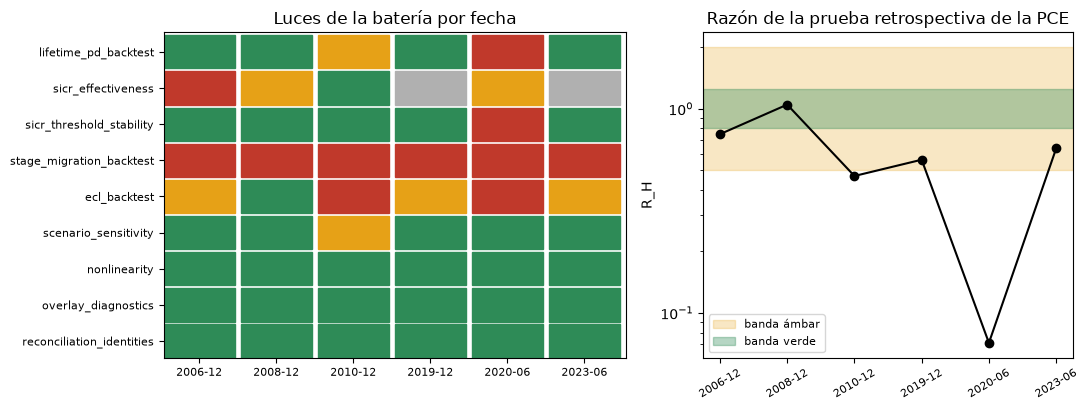

In [12]:
# Dibujar la grilla de luces y la razón de la prueba retrospectiva de la PCE por fecha
palette = {"green": "#2e8b57", "amber": "#e6a117", "red": "#c0392b", "not_evaluated": "#b0b0b0"}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for i, tid in enumerate(TEST_IDS):
    for j, d in enumerate(DATES):
        left.add_patch(plt.Rectangle((j, len(TEST_IDS) - 1 - i), 0.92, 0.92, color=palette[lights[tid][d]]))
left.set_xlim(0, len(DATES))
left.set_ylim(0, len(TEST_IDS))
left.set_xticks(np.arange(len(DATES)) + 0.46)
left.set_xticklabels(DATES, fontsize=8)
left.set_yticks(np.arange(len(TEST_IDS)) + 0.46)
left.set_yticklabels(TEST_IDS[::-1], fontsize=8)
left.set_title("Luces de la batería por fecha")

right.axhspan(0.5, 2.0, color="#e6a117", alpha=0.25, label="banda ámbar")
right.axhspan(0.8, 1.25, color="#2e8b57", alpha=0.35, label="banda verde")
right.plot(range(len(DATES)), [r_values[d] for d in DATES], marker="o", color="black")
right.set_yscale("log")
right.set_xticks(range(len(DATES)))
right.set_xticklabels(DATES, fontsize=8, rotation=30)
right.set_ylabel("R_H")
right.set_title("Razón de la prueba retrospectiva de la PCE")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **La batería en una tabla.** De las 54 celdas (nueve pruebas, seis fechas) 34 son verdes, 7 ámbar, 11 rojas y 2 no evaluadas. Tres pruebas son verdes en todas las fechas: la no linealidad, los diagnósticos de ajustes y las identidades de conciliación, que verifican la aritmética del motor y las tablas (cuadernos 03 y 04). Otra es roja en todas las fechas: la migración de etapas. Las columnas informativas son las demás.
- **La prueba de PD de vida completa depende de su regla.** En 2008 la mayor diferencia en la cohorte `all` es 0,01669 para el peldaño `L1-dth`, igual a la métrica versionada, y la PD acumulada observada está dentro de la banda versionada en los seis horizontes, así que la luz versionada es verde. La llamada sin $\rho$ usa la regla de la diferencia relativa, cuya mayor diferencia relativa es 0,3228, sobre el límite de 0,25, y da ámbar. Ninguna está equivocada: la banda dice que la diferencia es compatible con la correlación de incumplimientos que supone la política ($\rho = 0{,}12$), la diferencia relativa dice que la predicción a 36 meses se desvía en un tercio. Un validador reporta la regla junto con la luz.
- **El resultado agrupado esconde las cohortes.** La cohorte 2007 es ámbar para `L0-km` (0,1240) y `L2-cox` (0,1163) y verde para `L1-dth` (0,0859); a 36 meses se previó 0,1267 y se observó 0,2006. La cohorte 2008 es ámbar para `L2-cox`. En la cohorte agrupada `all` los tres peldaños son verdes con métricas de 0,0427, 0,0167 y 0,0427.
- **La calibración por decil no es monótona.** A 12 meses la razón entre lo observado y lo previsto es 0,97 en el decil 1, 2,14 en el decil 5, 0,50 en el decil 9 y 0,77 en el decil 10: los préstamos que el modelo llama más riesgosos incumplen menos de lo previsto y los del medio más. El orden de la predicción es solo vagamente el orden de los resultados.
- **La efectividad del SICR cambia de signo con la fecha.** La razón entre la tasa de incumplimiento de la Etapa 2 y la de la Etapa 1 es 0,9662 en 2006 (la Etapa 2 incumplió algo menos que la Etapa 1, roja, área bajo la curva ROC 0,4999), 2,2525 en 2008 (ámbar), 2,4376 en 2010 (verde) y 1,9951 en 2020-06 (ámbar, justo bajo el límite verde de 2). La división de los conteos versionados da las mismas razones. La proporción de los incumplidos que vinieron directamente de la Etapa 1 es 99,6 % en 2006, 90,7 % en 2008 y 15,3 % en 2010: en la crisis la mayoría de los incumplidos del año siguiente seguía en la Etapa 1 a la fecha de reporte.
- **La prueba de estabilidad del umbral se activa una vez.** Solo 2020-06 es roja (uno de dos períodos se relaja, que es la mitad). En series construidas el motor da verde para ninguno, ámbar para dos períodos que se relajan y rojo para cuatro de seis.
- **La prueba de migración de etapas es roja en todas partes, por una razón que un validador debe leer.** En 2006, 2008 y 2020-06 una observación cae en una celda a la que la matriz prevista asigna cero (estadístico infinito, valor p 0); en las otras fechas el estadístico es tan grande que el valor p es 0 (2010-12) o 1,2e-60 y 9,6e-33 (2019-12 y 2023-06). El artefacto no dice qué celda es imposible; las altas proporciones de incumplimientos que llegan a la Etapa 3 directamente desde la Etapa 1 son coherentes con ello. Los casos construidos muestran los dos lados: conteos cerca de la predicción dan un estadístico de 0,547 y un valor p de 0,9687, y conteos que se movieron dan 143,075.
- **La prueba retrospectiva de la PCE dice que la cobertura estuvo sobre la pérdida realizada en cinco de seis fechas.** $R_H$ es 0,7496, 1,046, 0,4678, 0,5619, 0,0713 y 0,6378, iguales a los valores y luces versionados. Solo 2008 es verde. En 2020-06 la pérdida descontada realizada es 313,1 millones de USD frente a una PCE de 4.393,5 millones, una razón de 0,0713, y la luz es roja.
- **La sensibilidad a los escenarios se recalcula exactamente,** y muestra que la PCE sube con la severidad del escenario en 2010-12, 2019-12 y 2023-06 y no en 2006-12, 2008-12 y 2020-06, las fechas que llevan el hallazgo `F-SCENARIO-ORDER`. En 2010-12 el índice es negativo ($-0{,}00071$), ámbar, porque una PCE ponderada bajo la PCE en la trayectoria media es inesperada para una pérdida convexa.
- **Una prueba que no se puede evaluar no es un aprobado.** En 2019-12 y 2023-06 no hay ninguna cuenta en la Etapa 2, así que la prueba de efectividad devuelve `not_evaluated` con una métrica indefinida. Las muestras construidas lo reproducen para ninguna cuenta en la Etapa 2 y para ningún incumplimiento en la Etapa 1. El informe debe decir que las etapas no se probaron en esas fechas.

Lo que este cuaderno no muestra: las versiones del motor difieren (las filas se calcularon con 0.5.0 y aquí se leen con 0.8.1), así que los recálculos son de las pruebas cuyos insumos guarda el archivo y coinciden con las filas versionadas en los dígitos impresos. Las luces son compuertas internas de Contraste, y los resultados observados son castigos de préstamos de la SBA, no incumplimientos de una cartera hipotecaria.

## Resumen

- La batería de IFRS 9 tiene nueve pruebas, cada una una función del motor que devuelve un `TestResult`, cada una una compuerta interna con sus parámetros registrados en la fila.
- Recalcula lo que permiten los insumos del artefacto (la prueba retrospectiva de la PCE, la sensibilidad a los escenarios, la métrica de vida completa, la razón del SICR por división) y lee el resto como filas versionadas.
- Una luz depende de su regla: la prueba de vida completa es verde con la banda de Vasicek y ámbar con la diferencia relativa sobre los mismos números, así que un informe enuncia la regla.
- El resultado agrupado esconde cohortes y deciles; la efectividad de las etapas cambia con la fecha y no es evaluable cuando no hay Etapa 2.
- Una prueba que no se puede evaluar es la ausencia de un resultado; la prueba de migración de etapas es roja en todas las fechas y la razón está en sus `extras`.

**Qué probar a continuación.** Abre las filas `L0-km` y `L2-cox` de 2008 y compara sus diferencias por cohorte con `L1-dth`; cambia la matriz `predicted` construida del paso 6 para que la celda en cero sea pequeña pero positiva. Después sigue con el cuaderno 06, que provisiona un banco bajo tres regímenes.

## Referencias

- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- EBA (2021), IFRS 9 implementation by EU institutions, informe de seguimiento, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuación (3.1). https://doi.org/10.1214/aoms/1177707039
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf